# Imagem digital

Tipo: <class 'numpy.ndarray'>
dtype: uint8
shape: (203, 284)
recorte 20x20:
 [[187 187 192 195 189 187 192 194 186 192 194 186 235 116  65  64  57  55
   55  57]
 [191 193 191 190 189 186 187 194 190 188 188 188 223 112  68  66  56  61
   65  65]
 [196 201 196 191 193 185 179 188 197 184 177 186 210  94  68  67  61  67
   66  58]
 [195 202 204 200 193 182 182 193 194 196 190 172 224 146  72  65  67  66
   59  58]
 [204 206 200 194 193 189 185 189 198 202 203 195 229 111  58  69  65  66
   61  59]
 [206 208 200 191 193 194 191 190 195 199 210 206 218  73  57  66  62  65
   62  59]
 [200 208 205 197 199 201 198 195 196 196 211 213 181  56  69  57  60  63
   59  57]
 [202 209 208 205 212 214 203 193 201 202 209 237 127  58  70  57  63  63
   57  55]
 [209 209 205 209 223 224 205 188 197 202 205 241  81  63  60  68  65  64
   57  57]
 [205 205 203 208 220 217 202 193 200 200 215 189  61  59  59  68  62  63
   59  58]
 [193 200 203 207 209 202 198 203 216 207 236 124  62  52  66  55  58  61

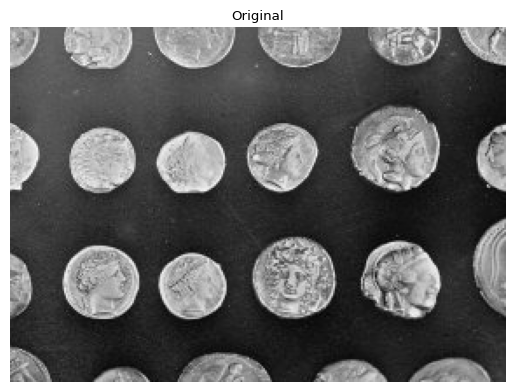

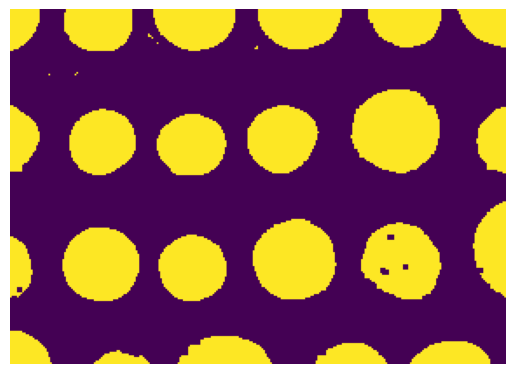

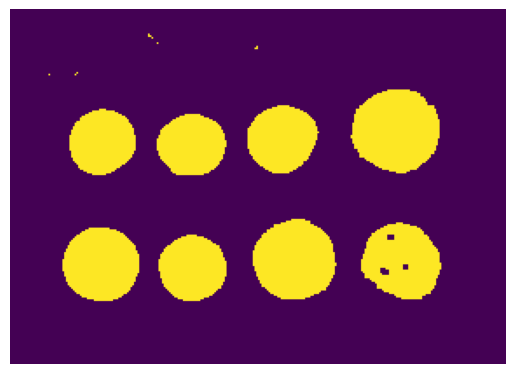

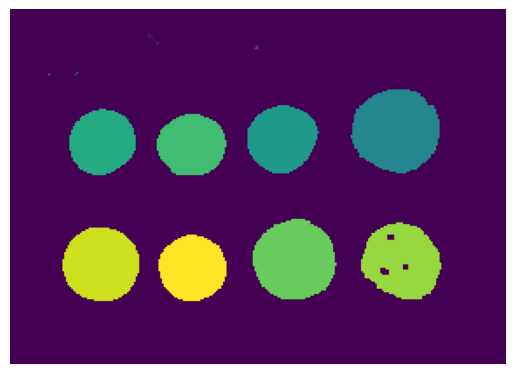

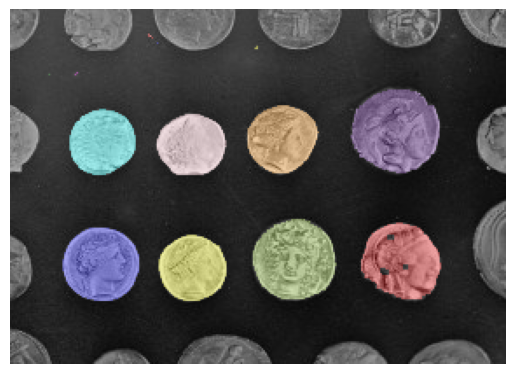

In [19]:
# adaptado de https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_label.html

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from skimage import data
from skimage.filters import threshold_otsu
from skimage.segmentation import clear_border
from skimage.measure import label, regionprops
from skimage.morphology import closing, footprint_rectangle
from skimage.color import label2rgb
import numpy as np

def mostra_imagem(img, titulo="", cmap="viridis"):
    plt.figure()
    plt.imshow(img, cmap=cmap)
    plt.title(titulo)
    plt.axis("off")
    plt.show()

def main():
  image = data.coins()[50:-50, 50:-50]

  print("Tipo:", type(image))
  print("dtype:", image.dtype)
  print("shape:", image.shape)
  print("recorte 20x20:\n", image[75:95, 110:130])

  mostra_imagem(image, titulo="Original", cmap='gray')

  # apply threshold
  thresh = threshold_otsu(image)
  bw = closing(image > thresh, footprint_rectangle((3, 3)))

  mostra_imagem(bw)

  # remove artifacts connected to image border
  cleared = clear_border(bw)

  mostra_imagem(cleared)

  # label image regions
  label_image = label(cleared)

  mostra_imagem(label_image)

  # to make the background transparent, pass the value of `bg_label`,
  # and leave `bg_color` as `None` and `kind` as `overlay`

  image_label_overlay = label2rgb(label_image, image=image, bg_label=0)

  mostra_imagem(image_label_overlay)


main()

# Amostragem e quantização

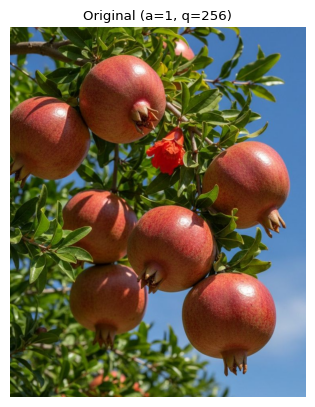

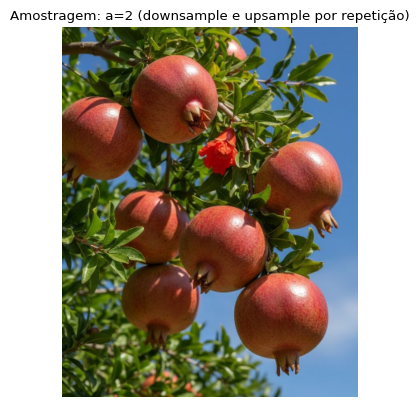

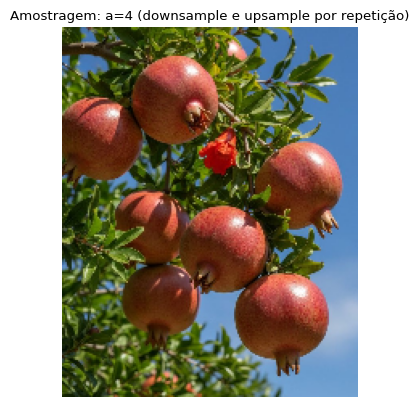

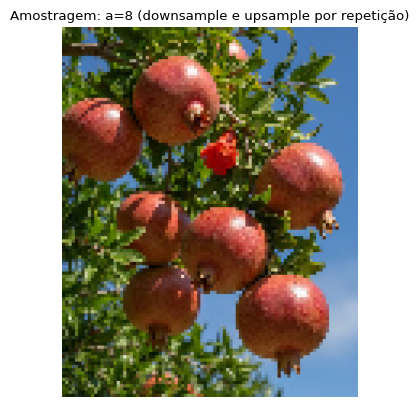

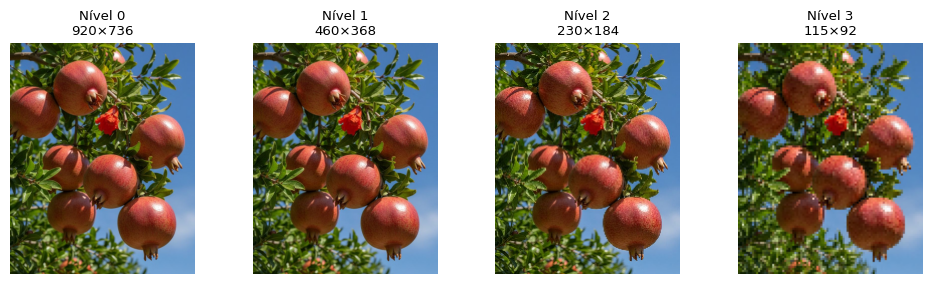

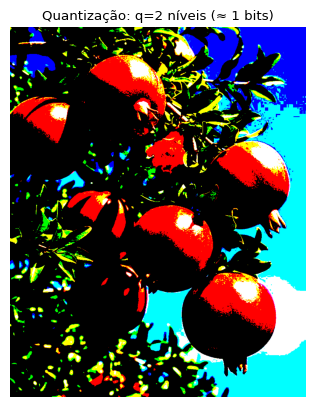

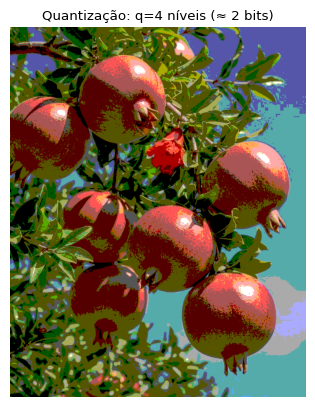

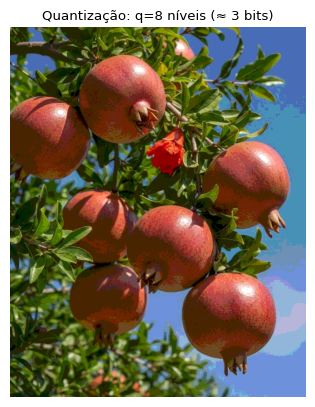

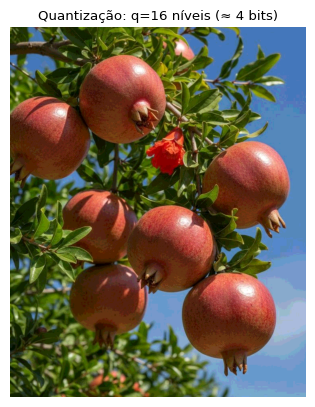

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

from PIL import Image
import cv2

def mostra_imagem(img, titulo="", cmap="gray"):
    plt.figure()
    plt.imshow(img, cmap=cmap)
    plt.title(titulo)
    plt.axis("off")
    plt.show()

def downsample_nearest(img, fator_a):
    return img[::fator_a, ::fator_a]

def upsample_nearest(img_small, fator_a):
    return np.repeat(np.repeat(img_small, fator_a, axis=0), fator_a, axis=1)

def quantiza_uniforme(img, niveis_q):
    img = img.astype(np.float32)
    img01 = img / 255.0
    # mapeia para 0..(q-1), arredonda e volta
    q = niveis_q
    imgq01 = np.round(img01 * (q - 1)) / (q - 1)
    return (imgq01 * 255.0).astype(np.uint8)

def mostra_piramide(image):
    piramide = [image]
    img = image
    for _ in range(3):
        img = downsample_nearest(img, 2)
        piramide.append(img)

    n = len(piramide)
    plt.figure(figsize=(12, 3))

    for i, img in enumerate(piramide):
        plt.subplot(1, n, i + 1)
        plt.imshow(img, cmap="gray")
        plt.title(f"Nível {i}\n{img.shape[0]}×{img.shape[1]}")
        plt.axis("off")

    plt.show()

def main():
    # imagem original (uint8, 0..255)
    image = Image.open('/content/data/Pomegranate.jpg')
    image = np.array(image) # Converte imagem PIL em matriz NumPy
    mostra_imagem(image, "Original (a=1, q=256)")

    # -------------------------
    # AMOSTRAGEM
    # -------------------------
    for a in [2, 4, 8]:
        img_small = downsample_nearest(image, a)
        img_vis = upsample_nearest(img_small, a)  # só para comparar no mesmo tamanho
        mostra_imagem(img_vis, f"Amostragem: a={a} (downsample e upsample por repetição)")

    # -------------------------
    # PIRÂMIDE
    # -------------------------
    mostra_piramide(image)

    # -------------------------
    # QUANTIZAÇÃO
    # -------------------------
    for q in [2, 4, 8, 16]:
        img_q = quantiza_uniforme(image, q)
        mostra_imagem(img_q, f"Quantização: q={q} níveis (≈ {int(np.log2(q))} bits)")


main()


# Processamento pontual

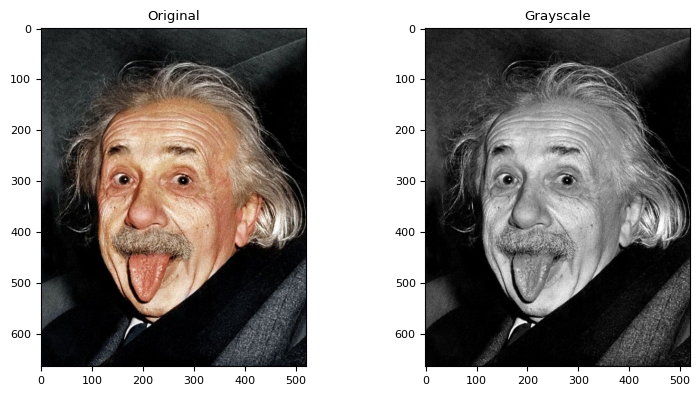

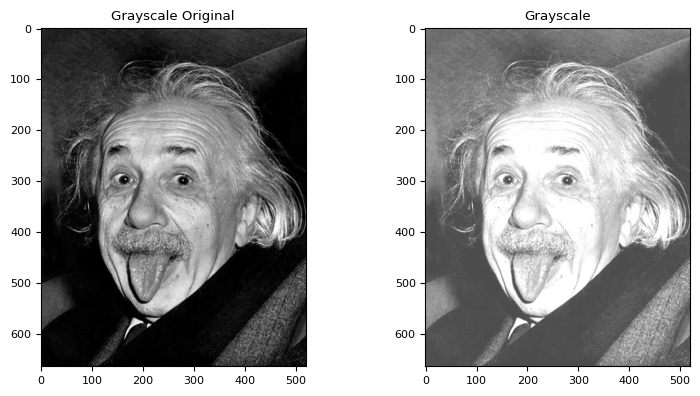

In [18]:
# Adaptado de https://scikit-image.org/docs/stable/auto_examples/color_exposure/plot_rgb_to_gray.html

import matplotlib.pyplot as plt

from skimage import data
from skimage.color import rgb2gray

from PIL import Image
import cv2

original = Image.open('/content/data/AlbertEinstein.jpg')
original = np.array(original) # Converte imagem PIL em matriz NumPy
grayscale = rgb2gray(original)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
ax = axes.ravel()

ax[0].imshow(original)
ax[0].set_title("Original")
ax[1].imshow(grayscale, cmap=plt.cm.gray)
ax[1].set_title("Grayscale")

fig.tight_layout()
plt.show()

grayscale_claro = grayscale + 0.3

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
ax = axes.ravel()

ax[0].imshow(grayscale, cmap=plt.cm.gray)
ax[0].set_title("Grayscale Original")
ax[1].imshow(grayscale_claro, cmap='gray', vmin=0, vmax=1)
ax[1].set_title("Grayscale")

fig.tight_layout()
plt.show()


# Formação de um dataset do curso

Inicialmente, o estudante deve escolher **2 classes** de objetos diferentes (ex.: caneca e copo) e, para cada classe, selecionar **2 objetos distintos**. Devem ser feitas 3 fotos por objeto.   Dessa forma, a base de imagens deve conter fotos com as seguintes características:

- **2 classes**
- **2 objetos por classe**
- **3 fotos** por objeto
- **tamanho do dataset**: 12 amostras

Um exemplo de [dataset está disponível aqui.](https://photos.app.goo.gl/oHBNTwJfNMbcPcwk6)

O dataset deve ser usado para testar os métodos apresentados no curso. Assim, os estudantes podem ver o efeito dos métodos aprendidos em seus próprios dados.


In [4]:
import matplotlib.pyplot as plt
from skimage import data
from skimage.color import rgb2gray
from google.colab import files
from skimage.io import imread
from PIL import Image, ImageOps
import numpy as np
from skimage.transform import resize

def data_loader(target_height=512):
    uploaded = files.upload()
    imagens = []

    for fname in uploaded.keys():
        # 1) Leitura com correção de EXIF
        img_pil = Image.open(fname)
        img_pil = ImageOps.exif_transpose(img_pil)
        img = np.array(img_pil)

        # 2) Normalização espacial (altura fixa)
        H, W = img.shape[:2]
        scale = target_height / H
        new_W = int(W * scale)

        img_resized = resize(
            img,
            (target_height, new_W),
            preserve_range=True,
            anti_aliasing=True
        ).astype(img.dtype)

        imagens.append(img_resized)

    print(f"{len(imagens)} imagens carregadas, corrigidas (EXIF) e normalizadas (H={target_height}).")
    return imagens

def clarear(original):
  grayscale = rgb2gray(original)
  grayscale_claro = grayscale + 0.3

  fig, axes = plt.subplots(1, 2, figsize=(8, 4))
  ax = axes.ravel()

  ax[0].imshow(grayscale, cmap=plt.cm.gray)
  ax[0].set_title("Grayscale Original")
  ax[1].imshow(grayscale_claro, cmap='gray', vmin=0, vmax=1)
  ax[1].set_title("Grayscale")

  fig.tight_layout()
  plt.show()


def visualize_dataset_array(imgs, m, n, grayscale=False, titles=None):
    total = m * n
    k = min(total, len(imgs))

    fig, axes = plt.subplots(m, n, figsize=(2*n, 2*m))
    axes = np.array(axes).reshape(m, n)

    for idx in range(total):
        ax = axes[idx // n, idx % n]
        ax.axis("off")

        if idx >= k:
            continue

        img = imgs[idx]

        if grayscale and img.ndim == 3:
            img = rgb2gray(img)
            ax.imshow(img, cmap="gray", vmin=0, vmax=1)
        else:
            # Se já for 2D, mostra como gray por padrão
            if img.ndim == 2:
                ax.imshow(img, cmap="gray")
            else:
                ax.imshow(img)

        if titles is not None and idx < len(titles):
            ax.set_title(titles[idx], fontsize=9)

    plt.tight_layout()
    plt.show()


def main():
    imagens = data_loader()

    visualize_dataset_array(imagens, 3, 4, False)

    for i, img in enumerate(imagens):
        print(f"Imagem {i+1}: shape={img.shape}, dtype={img.dtype}")
        clarear(img)

main()

Output hidden; open in https://colab.research.google.com to view.

# Manipulação de histogramas

Saving controle-2.jpeg to controle-2 (1).jpeg
1 imagens carregadas, corrigidas (EXIF) e normalizadas (H=256).
Imagem 1: shape=(256, 192), dtype=float64


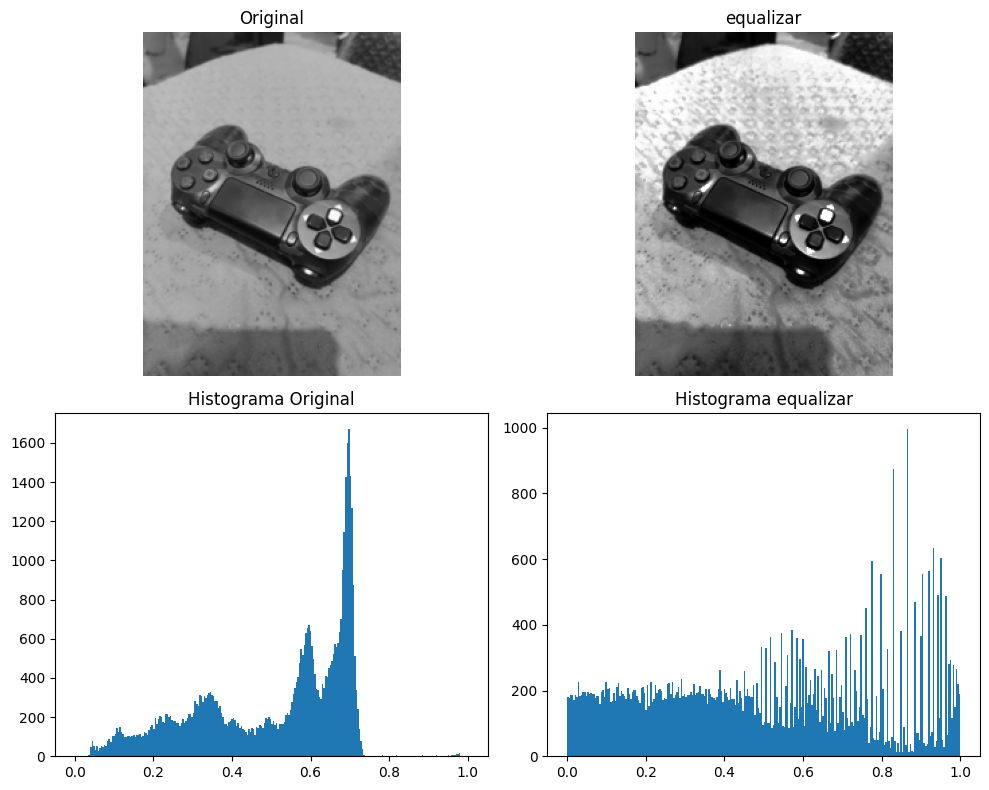

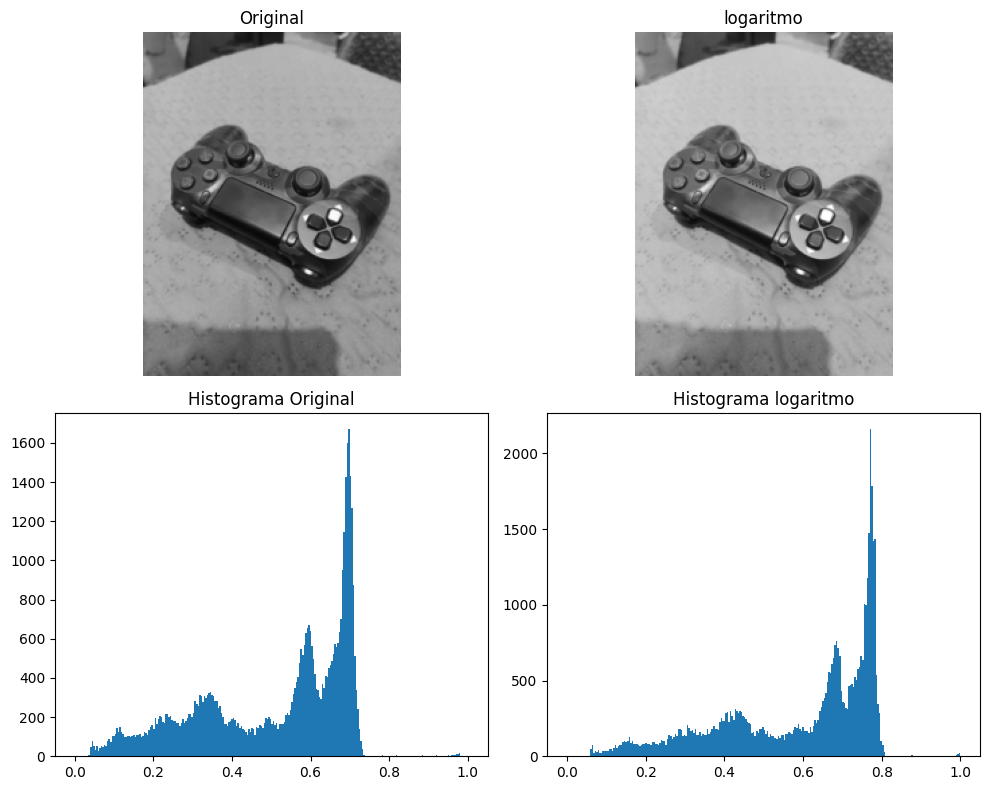

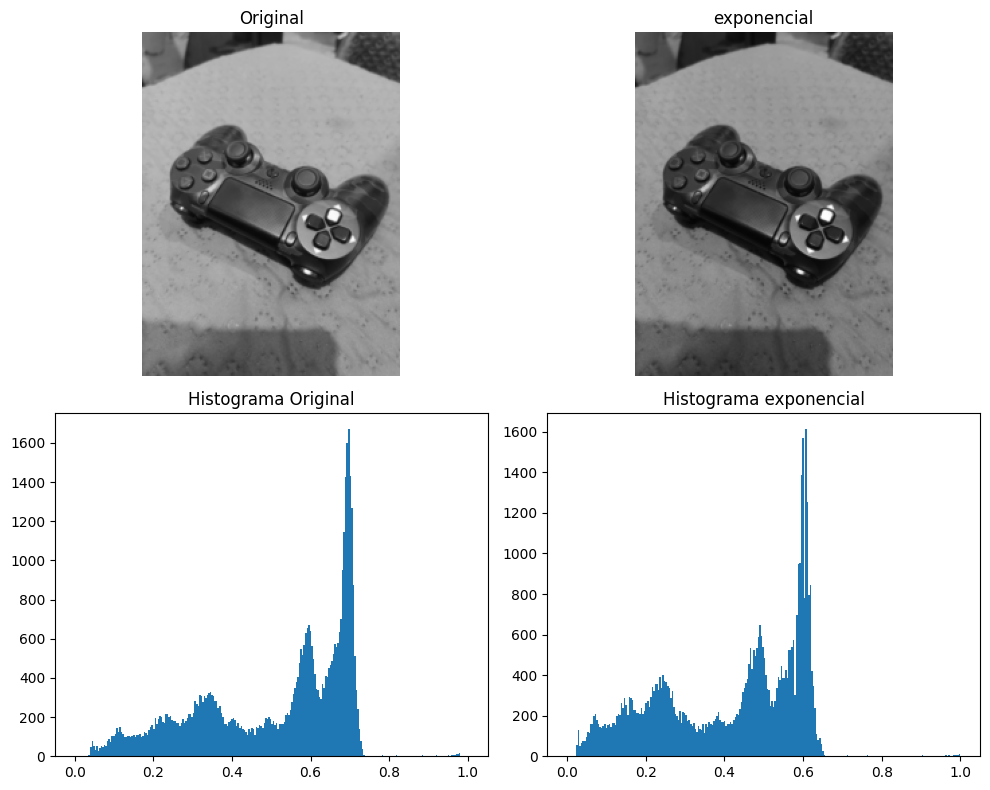

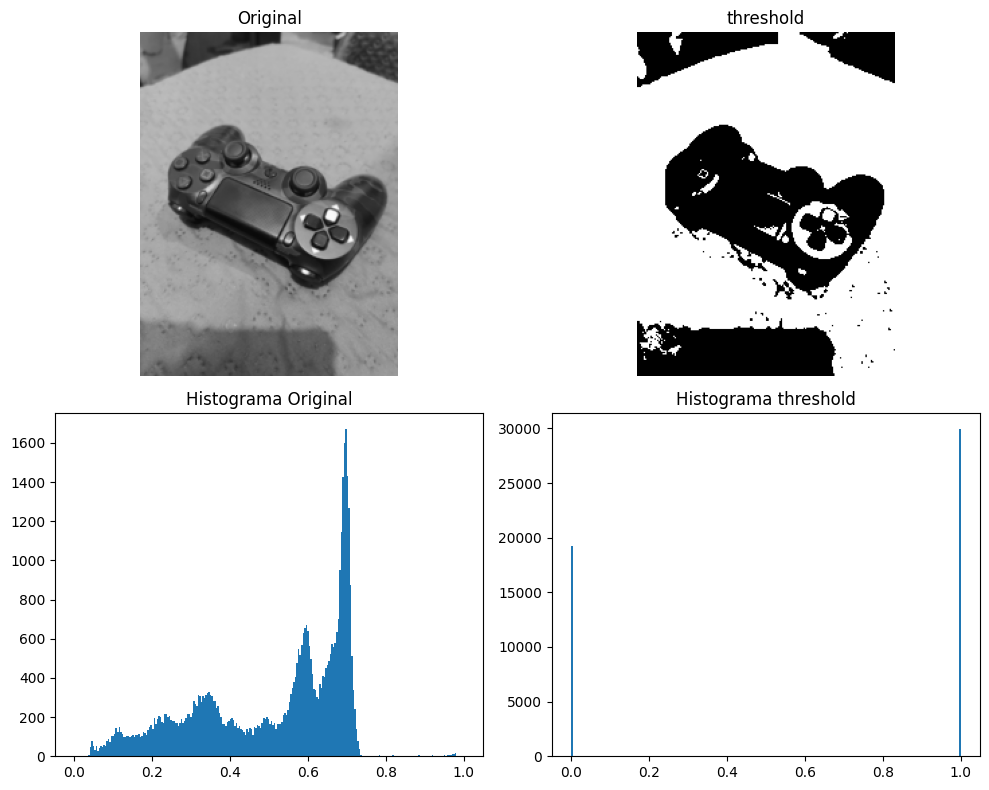

In [8]:
import matplotlib.pyplot as plt
from skimage import data
from skimage.color import rgb2gray
from google.colab import files
from skimage.io import imread
from PIL import Image, ImageOps
import numpy as np
from skimage.transform import resize
import skimage.exposure as exposure

def data_loader(target_height=512):
    uploaded = files.upload()
    imagens = []

    for fname in uploaded.keys():
        # 1) Leitura com correção de EXIF
        img_pil = Image.open(fname)
        img_pil = ImageOps.exif_transpose(img_pil)
        img = np.array(img_pil)

        # 2) Normalização espacial (altura fixa)
        H, W = img.shape[:2]
        scale = target_height / H
        new_W = int(W * scale)

        img_resized = resize(
            img,
            (target_height, new_W),
            preserve_range=True,
            anti_aliasing=True
        ).astype(img.dtype)

        imagens.append(img_resized)

    print(f"{len(imagens)} imagens carregadas, corrigidas (EXIF) e normalizadas (H={target_height}).")
    return imagens


def mostra_imagem(img, titulo="", cmap="gray"):
    plt.figure()
    plt.imshow(img, cmap=cmap)
    plt.title(titulo)
    plt.axis("off")
    plt.show()


def mostra_compara(img1, img2, t1='img1', t2='img2'):
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))

    # --- Imagens ---
    axes[0, 0].imshow(img1, cmap="gray", vmin=0, vmax=1)
    axes[0, 0].set_title(t1)
    axes[0, 0].axis("off")

    axes[0, 1].imshow(img2, cmap="gray", vmin=0, vmax=1)
    axes[0, 1].set_title(t2)
    axes[0, 1].axis("off")

    # --- Histogramas ---
    axes[1, 0].hist(img1.ravel(), bins=256, range=(0, 1))
    axes[1, 0].set_title(f"Histograma {t1}")

    axes[1, 1].hist(img2.ravel(), bins=256, range=(0, 1))
    axes[1, 1].set_title(f"Histograma {t2}")

    fig.tight_layout()
    plt.show()



def altera_histograma(img, funcao='equalizar'):
    if funcao == "equalizar":
        img2 = exposure.equalize_hist(img)

    elif funcao == "logaritmo":
        # realça regiões escuras
        img2 = np.log1p(img)
        img2 = img2 / img2.max()

    elif funcao == "exponencial":
        # realça regiões claras
        img2 = np.expm1(img)
        img2 = img2 / img2.max()

    elif funcao == "threshold":
        img2 = (img >= 0.5).astype(float)

    return img2


def main():
    imagens = data_loader(target_height=256)

    for i, img in enumerate(imagens):
        img = rgb2gray(img)
        print(f"Imagem {i+1}: shape={img.shape}, dtype={img.dtype}")
        funcao = ['equalizar', 'logaritmo', 'exponencial', 'threshold']
        for f in funcao:
          img2=altera_histograma(img, f)
          mostra_compara(img, img2, t1='Original', t2=f)

main()

# Média de imagens para filtragem

In [9]:
import matplotlib.pyplot as plt
from skimage import data
from skimage.color import rgb2gray
from google.colab import files
from skimage.io import imread
from PIL import Image, ImageOps
import numpy as np
from skimage.transform import resize

def data_loader(target_height=512):
    uploaded = files.upload()
    imagens = []

    for fname in uploaded.keys():
        # 1) Leitura com correção de EXIF
        img_pil = Image.open(fname)
        img_pil = ImageOps.exif_transpose(img_pil)
        img = np.array(img_pil)

        # 2) Normalização espacial (altura fixa)
        H, W = img.shape[:2]
        scale = target_height / H
        new_W = int(W * scale)

        img_resized = resize(
            img,
            (target_height, new_W),
            preserve_range=True,
            anti_aliasing=True
        ).astype(img.dtype)

        imagens.append(img_resized)

    print(f"{len(imagens)} imagens carregadas, corrigidas (EXIF) e normalizadas (H={target_height}).")
    return imagens


def mostra_imagem(img, titulo="", cmap="gray"):
    plt.figure()
    plt.imshow(img, cmap=cmap)
    plt.title(titulo)
    plt.axis("off")
    plt.show()


def gera_ruido(original, noise_type="gaussian", noise_level=0.02):
    grayscale = rgb2gray(original)

    # --- Adição de ruído ---
    if noise_type == "gaussian":
        noise = np.random.normal(0, noise_level, grayscale.shape)
        grayscale_ruido = grayscale + noise
    else: # "salt_pepper"
        grayscale_ruido = grayscale.copy()
        p = noise_level  # fração de pixels afetados

        # máscaras aleatórias
        rnd = np.random.rand(*grayscale.shape)
        grayscale_ruido[rnd < p / 2] = 0      # pimenta
        grayscale_ruido[rnd > 1 - p / 2] = 1  # sal

    # Garante faixa válida
    grayscale_ruido = np.clip(grayscale_ruido, 0, 1)
    return(grayscale_ruido)


def mostra_compara(img1, img2,  t1='img1', t2='img2'):
    # --- Visualização ---
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    ax = axes.ravel()

    ax[0].imshow(img1, cmap="gray")
    ax[0].set_title(t1)

    ax[1].imshow(img2, cmap="gray", vmin=0, vmax=1)
    ax[1].set_title(t2)

    for a in ax:
        a.axis("off")

    fig.tight_layout()
    plt.show()

def main():
    imagens = data_loader(target_height=256)
    n_imagens = len(imagens)

    lins,cols, bands = imagens[0].shape

    n_noisy_samples = 10

    for i, img in enumerate(imagens):
      soma_gaussian = np.zeros((lins,cols))
      soma_sp = np.zeros((lins,cols))

      for j in range(n_noisy_samples):
        print(f"Imagem {i+1}: shape={img.shape}, dtype={img.dtype}")
        img2=gera_ruido(img, noise_type="gaussian", noise_level=0.05)
        soma_gaussian += img2
        mostra_compara(img, img2, t1='Original', t2='Ruido Gaussiano')

      mostra_imagem(soma_gaussian / n_noisy_samples, titulo='Media Ruido Gaussiano')

      for j in range(n_noisy_samples):
        print(f"Imagem {i+1}: shape={img.shape}, dtype={img.dtype}")
        img2=gera_ruido(img, noise_type="salt_pepper")
        soma_sp += img2
        mostra_compara(img, img2, t1='Original', t2='Salt & Pepper')

      mostra_imagem(soma_sp / n_noisy_samples, titulo='Media Salt & Pepper')


main()

Output hidden; open in https://colab.research.google.com to view.

# Equalização de Histograma

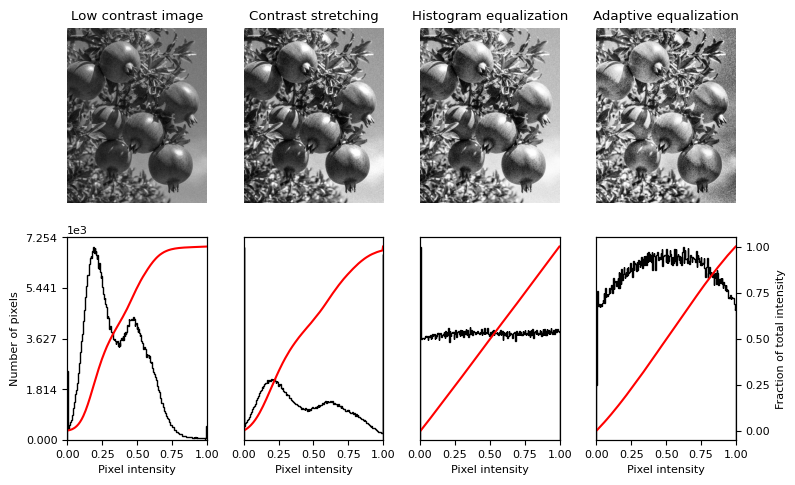

In [15]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

from skimage import data, img_as_float
from skimage import exposure

from PIL import Image
import cv2


matplotlib.rcParams['font.size'] = 8

def gera_ruido(original, noise_type="gaussian", noise_level=0.02):
    grayscale = rgb2gray(original)

    # --- Adição de ruído ---
    if noise_type == "gaussian":
        noise = np.random.normal(0, noise_level, grayscale.shape)
        grayscale_ruido = grayscale + noise
    else: # "salt_pepper"
        grayscale_ruido = grayscale.copy()
        p = noise_level  # fração de pixels afetados

        # máscaras aleatórias
        rnd = np.random.rand(*grayscale.shape)
        grayscale_ruido[rnd < p / 2] = 0      # pimenta
        grayscale_ruido[rnd > 1 - p / 2] = 1  # sal

    # Garante faixa válida
    grayscale_ruido = np.clip(grayscale_ruido, 0, 1)
    return(grayscale_ruido)

def plot_img_and_hist(image, axes, bins=256):
    """Plot an image along with its histogram and cumulative histogram."""
    image = img_as_float(image)
    ax_img, ax_hist = axes
    ax_cdf = ax_hist.twinx()

    # Display image
    ax_img.imshow(image, cmap=plt.cm.gray)
    ax_img.set_axis_off()

    # Display histogram
    ax_hist.hist(image.ravel(), bins=bins, histtype='step', color='black')
    ax_hist.ticklabel_format(axis='y', style='scientific', scilimits=(0, 0))
    ax_hist.set_xlabel('Pixel intensity')
    ax_hist.set_xlim(0, 1)
    ax_hist.set_yticks([])

    # Display cumulative distribution
    img_cdf, bins = exposure.cumulative_distribution(image, bins)
    ax_cdf.plot(bins, img_cdf, 'r')
    ax_cdf.set_yticks([])

    return ax_img, ax_hist, ax_cdf


# Load an example image
img = Image.open('/content/data/Pomegranate.jpg')
img = np.array(img) # Converte imagem PIL em matriz NumPy

img = gera_ruido(img, noise_type="gaussian", noise_level=0.05)

# Contrast stretching
p2, p98 = np.percentile(img, (2, 98))
img_rescale = exposure.rescale_intensity(img, in_range=(p2, p98))

# Equalization
img_eq = exposure.equalize_hist(img)

# Adaptive Equalization
img_adapteq = exposure.equalize_adapthist(img, clip_limit=0.03)

# Display results
fig = plt.figure(figsize=(8, 5))
axes = np.zeros((2, 4), dtype=object)
axes[0, 0] = fig.add_subplot(2, 4, 1)
for i in range(1, 4):
    axes[0, i] = fig.add_subplot(2, 4, 1 + i, sharex=axes[0, 0], sharey=axes[0, 0])
for i in range(0, 4):
    axes[1, i] = fig.add_subplot(2, 4, 5 + i)

ax_img, ax_hist, ax_cdf = plot_img_and_hist(img, axes[:, 0])
ax_img.set_title('Low contrast image')

y_min, y_max = ax_hist.get_ylim()
ax_hist.set_ylabel('Number of pixels')
ax_hist.set_yticks(np.linspace(0, y_max, 5))

ax_img, ax_hist, ax_cdf = plot_img_and_hist(img_rescale, axes[:, 1])
ax_img.set_title('Contrast stretching')

ax_img, ax_hist, ax_cdf = plot_img_and_hist(img_eq, axes[:, 2])
ax_img.set_title('Histogram equalization')

ax_img, ax_hist, ax_cdf = plot_img_and_hist(img_adapteq, axes[:, 3])
ax_img.set_title('Adaptive equalization')

ax_cdf.set_ylabel('Fraction of total intensity')
ax_cdf.set_yticks(np.linspace(0, 1, 5))

# prevent overlap of y-axis labels
fig.tight_layout()
plt.show()